# PZ data challenge: task set 3 within and across simulations

How well do the task set 3 (spec + COSMOS) models trained on Flagship do on Flagship, and on Cardinal, a simulation they never saw? Four evaluations: Y1 and Y10, each tested on

- **Flagship → Flagship**: the held-out 20% of the Flagship training file (`train_test_split` with `VAL_FRAC` and `SEED`, as in the task-set notebook; the model was trained on the other 80%), and
- **Flagship → Cardinal**: the same 20% split of the Cardinal training file.

The model is the one of the task-set notebooks, after the moment networks of Jeffrey & Wandelt 2020 (arXiv:2011.05991): F, a `znn.build_model` network, predicts log(1 + z), then G, a new instance of the same architecture trained on F's residuals with F fixed, learns the scale of a Student-t with `NU` degrees of freedom by its negative log-likelihood. The p(z) is that Student-t in log(1 + z) around F's prediction (`znn.predict`), on the photometry as given: G's scale already includes the photometric noise of the observed data, so drawing noise on top would count it twice.

The model is compared with BPZ (Benítez 2000), a template-fitting code, run through RAIL's `BPZlite` on the same splits. Its templates are fixed, and its prior is fitted on the same 80% of the Flagship training file the model is trained on, so both methods see the same training redshifts and Flagship → Cardinal is a transfer test for both.

The run is set by `PRETRAINING` (F from scratch, or from its pop-cosmos pre-training), and its directory `OUT_DIR` follows from it, as the task-set notebooks name it.

The notebook is self-contained: if the run's trained models (the subtask 2 `.pkl` model files) are not in `OUT_DIR`, it trains them on the same split and with the same settings as `pz_challenge_taskset3_e2e.ipynb` and saves them there; if they are, it uses them. The p(z)s are predicted here with the current `znn` code, and scored with the challenge metrics and on their stacked n(z).

The held-out predictions are cached in `<OUT_DIR>_predictions`, shared with `pz_challenge_results.ipynb` (the mock evaluation of all task sets, for submissions). Delete the cache to recompute, e.g. after changing how `znn` builds the p(z). BPZ's fitted priors are saved in `BPZ_DIR` and its held-out predictions cached in `<BPZ_DIR>_predictions`; delete them after changing a BPZ setting. Figures (`.pdf`) and LaTeX tables (`.tex`) are saved to `PLOT_DIR`, prefixed so they never overwrite those of `pz_challenge_results.ipynb`.

Run this from the repo root with the `qp` conda env as the kernel.

## Configuration

In [1]:
import znn  # run from the repo root so this picks up the local source

# the models: task set TASKSET trained on TRAIN_SIM at each depth, tested on the held-out split of each of TEST_SIMS
TASKSET = 3
TRAIN_SIM = "flagship"
TEST_SIMS = ["flagship", "cardinal"]
SCENARIOS = ["1yr", "10yr"]

DATA_DIR = "../pz_data_challenge/scripts/public"  # as in the task-set notebooks
# The run, trained below if its model files are not in OUT_DIR. PRETRAINING: "popcosmos" (the pre-training of F
# shipped with znn, only the starting point of its weights) or None (from scratch); G always starts from scratch
PRETRAINING = "popcosmos"
NU = znn.DEFAULT_NU  # degrees of freedom of G's Student-t
# The directory of the run's model files, as the task-set notebooks name it: "build_model_res_se_log1pz" (the name
# znn.build_model had when it was added, which keeps its runs apart from those of the old model), then "moment_t"
# and NU
OUT_DIR = ("outputs/znn" if PRETRAINING is None else f"outputs/znn_pretrained_{PRETRAINING}") + f"_build_model_res_se_log1pz_moment_t{NU:g}"
PLOT_DIR = "plots"  # figures and LaTeX tables are saved here, prefixed with the run name and the evaluation

# the held-out split: must match the task-set notebook
VAL_FRAC = 0.2
SEED = 42
NZ_SEED = 42  # of the redshifts drawn from the p(z)s for the n(z) check
# training, only of a run whose model files are missing: as in the task-set notebook
EPOCHS = 100  # max epochs of F and of G (early stopping usually ends sooner)

# BPZ, the template-fitting baseline (rail_bpz's BPZlite). Templates and settings follow the challenge's accepted BPZ
# submissions (accepted/test_bpz_31temps_4tasks.py): the 31 COSMOS templates in 3 broad types, a Gaussian smoothing
# kernel and Madau absorption. Their kernel and Madau flag are those they use on Flagship; they are kept for Cardinal
# too (the challenge submission switches to 0.04 and no Madau there), so BPZ, like the model, is tuned on Flagship only
BPZ_DIR = f"outputs/bpz_taskset{TASKSET}_{TRAIN_SIM}"  # the fitted priors; held-out predictions in <BPZ_DIR>_predictions
BPZ_SPECTRA = "COSMOS_seds.list"  # template list, in RAIL's examples_data/estimation_data/data/SED
BPZ_NT = [10, 9, 12]  # templates per broad type (elliptical, spiral, starburst), in the order of BPZ_SPECTRA
BPZ_KERNEL = 0.12  # width in z of the Gaussian the p(z) is smoothed with
BPZ_MADAU = "yes"  # IGM absorption in the template fluxes

I0000 00:00:1793870867.664287 1718844 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
import itertools
import os
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import qp
from qp.metrics.pit import PIT
from sklearn.model_selection import train_test_split

os.makedirs(PLOT_DIR, exist_ok=True)

# the task set's colour, as in pz_challenge_results.ipynb; its colour map is used for 2D densities
TASKSET_CMAPS = {1: "Blues", 2: "Greens", 3: "Oranges", 4: "Purples"}
CMAP = TASKSET_CMAPS[TASKSET]
COLOR = plt.get_cmap(CMAP)(0.7)
TRAIN_COLOR = "0.6"
# how sims and depths are written in plots and tables
SIM_LABELS = {"cardinal": "Cardinal", "flagship": "Flagship"}
DEPTH_LABELS = {"1yr": "Y1", "10yr": "Y10"}
INDEX_LABELS = {"test": "Tested on", "scenario": "Depth", "method": "Method"}
# the methods compared: the model ("znn") and the template-fitting baseline ("bpz")
METHODS = ["znn", "bpz"]
METHOD_LABELS = {"znn": "znn", "bpz": "BPZ"}
METHOD_CMAPS = {"znn": CMAP, "bpz": "Greys"}
METHOD_COLORS = {m: plt.get_cmap(c)(0.7) for m, c in METHOD_CMAPS.items()}
# prefix of the saved figures and tables
PREFIX = f"{os.path.basename(OUT_DIR)}_taskset{TASKSET}_{TRAIN_SIM}_transfer"


def transfer_label(test_sim):
    # training -> test simulation
    return f"{SIM_LABELS[TRAIN_SIM]} → {SIM_LABELS[test_sim]}"


def save(fig, name):
    fig.savefig(os.path.join(PLOT_DIR, f"{PREFIX}_{name}.pdf"), bbox_inches="tight")


def save_latex(df, name, columns, caption):
    # Write df as a booktabs LaTeX table (columns: {df column: LaTeX header}) to PLOT_DIR and print it. Values of
    # 10 or more (the Anderson-Darling statistic) get one decimal, the rest four.
    df = df[list(columns)].rename(columns=columns, index=SIM_LABELS | DEPTH_LABELS | METHOD_LABELS)
    tex = df.rename_axis([INDEX_LABELS[n] for n in df.index.names]).to_latex(
        float_format=lambda v: f"{v:.1f}" if abs(v) >= 10 else f"{v:.4f}", multirow=True, caption=caption,
        label=f"tab:{name}", position="htbp",
    )
    # a rule between groups of the first index level only
    tex = re.sub(r"^(?:\\cline\{\d+-\d+\} ?)+\n", lambda m: "\\midrule\n" if "\\cline{1-" in m[0] else "", tex, flags=re.M)
    tex = tex.replace("\\midrule\n\\bottomrule", "\\bottomrule")
    with open(os.path.join(PLOT_DIR, f"{PREFIX}_{name}.tex"), "w") as f:
        f.write(tex)
    print(tex)


def path(kind, taskset, sim, scenario):
    if kind in ("training", "test"):
        return os.path.join(DATA_DIR, f"pz_challenge_taskset_{taskset}_{sim}_{kind}_{scenario}.hdf5")
    return os.path.join(OUT_DIR, f"pz_challenge_taskset_{taskset}_{sim}_{kind}_{scenario}.pkl")


def cache_stem(taskset, sim, scenario, test_sim, run_dir=OUT_DIR):
    # the cached held-out predictions of the run in run_dir (the model, or BPZ in BPZ_DIR) trained on sim, on
    # test_sim's held-out split
    on = "" if test_sim == sim else f"_on_{test_sim}"
    return os.path.join(f"{run_dir}_predictions", f"taskset_{taskset}_{sim}{on}_{scenario}_pz")

## Reference redshifts

These are the same labels as in the task-set notebooks: `redshift` for spectroscopically selected objects and `redshift_manyband` for COSMOS-only objects, so the scores include the label noise of the COSMOS-only objects, on both simulations.


In [3]:
SPEC_SURVEYS = ["DEEP2_LSST", "DESI_BGS", "DESI_ELG_LOP", "DESI_LRG", "VVDSf02", "zCOSMOS"]


def reference_redshifts(train):
    # Reference redshift per training object.
    z_spec = train["redshift"].to_numpy()
    if "COSMOS" not in train:  # task sets 1 and 2
        return z_spec
    is_spec = train[[c for c in SPEC_SURVEYS if c in train]].astype(bool).any(axis=1).to_numpy()
    is_cosmos_only = train["COSMOS"].astype(bool).to_numpy() & ~is_spec
    z_ref = np.where(is_cosmos_only, train["redshift_manyband"].to_numpy(), z_spec)
    assert np.isfinite(z_ref).all()
    return z_ref


## Train the model (only if needed)

For each depth whose model file is not in `OUT_DIR`, the model is trained on the Flagship training file minus the held-out split, on the photometry as given, as in `pz_challenge_taskset3_e2e.ipynb` (`znn.train_model`), and saved there. F is trained first (a random `VAL_FRAC` of the fit set held out for early stopping), from scratch or from the pre-trained weights, every layer trainable; then G, from scratch, on F's residuals on the same objects, with F fixed. Both are saved in one model file, and their training and validation losses are saved to `PLOT_DIR` as `<prefix>_losses_<depth>.pdf`.

Any cached held-out predictions of a depth trained here are deleted, since they came from an older model. Depths whose model file exists are not retrained; delete the file to retrain.

In [4]:
from rail.utils.path_utils import find_rail_file

# Filter curves shipped with RAIL; the challenge's catalogs.yaml ("cardinal_roman_rubin") maps the catalogue columns
# to these DC2LSST_* and roman_* filters. As in the task-set notebook
FILTER_DIR = find_rail_file("examples_data/estimation_data/data/FILTER")
# band -> (catalogue magnitude column, filter curve file), ordered by wavelength
BANDS = {
    "u": ("mag_u_lsst", f"{FILTER_DIR}/DC2LSST_u.res"),
    "g": ("mag_g_lsst", f"{FILTER_DIR}/DC2LSST_g.res"),
    "r": ("mag_r_lsst", f"{FILTER_DIR}/DC2LSST_r.res"),
    "i": ("mag_i_lsst", f"{FILTER_DIR}/DC2LSST_i.res"),
    "z": ("mag_z_lsst", f"{FILTER_DIR}/DC2LSST_z.res"),
    "y": ("mag_y_lsst", f"{FILTER_DIR}/DC2LSST_y.res"),
    "Y": ("mag_Y_roman", f"{FILTER_DIR}/roman_Y106.res"),
    "J": ("mag_J_roman", f"{FILTER_DIR}/roman_J129.res"),
    "H": ("mag_H_roman", f"{FILTER_DIR}/roman_H158.res"),
}
REF_BAND = "i"  # magnitudes are normalized by this band
FEATURE_CONFIG = znn.DEFAULT_FEATURE_CONFIG

os.makedirs(OUT_DIR, exist_ok=True)
for scenario in SCENARIOS:
    model_file = path("pz_model", TASKSET, TRAIN_SIM, scenario)
    if os.path.exists(model_file):
        print("found", model_file)
        continue
    print(f"\n========== training: task set {TASKSET} {TRAIN_SIM} {scenario} ==========")
    train = znn.read_catalog(path("training", TASKSET, TRAIN_SIM, scenario))
    z_ref = reference_redshifts(train)
    # the held-out split is left out of training: it is what the model is scored on
    idx_fit, _ = train_test_split(np.arange(len(train)), test_size=VAL_FRAC, random_state=SEED)
    model, histories = znn.train_model(
        znn.build_model, train.iloc[idx_fit], BANDS, REF_BAND, FEATURE_CONFIG, Y=z_ref[idx_fit],
        nu=NU, EPOCHS=EPOCHS, random_state=SEED, pretraining=PRETRAINING,
    )
    fig = znn.plot_losses(histories)  # in the standardised log(1 + z) of F
    save(fig, f"losses_{scenario}")
    znn.save_model_file(model_file, model, BANDS, REF_BAND, FEATURE_CONFIG)
    print("saved", model_file)

    # held-out predictions cached from an earlier model of this depth are stale now
    for test_sim in TEST_SIMS:
        for ext in ("npz", "hdf5"):
            if os.path.exists(stale := f"{cache_stem(TASKSET, TRAIN_SIM, scenario, test_sim)}.{ext}"):
                os.remove(stale)
                print("removed stale", stale)

found outputs/znn_pretrained_popcosmos_build_model_res_se_log1pz_moment_t5/pz_challenge_taskset_3_flagship_pz_model_1yr.pkl
found outputs/znn_pretrained_popcosmos_build_model_res_se_log1pz_moment_t5/pz_challenge_taskset_3_flagship_pz_model_10yr.pkl


## Fit BPZ (only if needed)

BPZ computes, for each object, the likelihood of its photometry for every template at every redshift on a grid (0 to 3 in steps of 0.01), multiplies it by a prior p(z, type | m_i), and sums over templates to get the p(z). The templates are fixed; what is trained is the prior: the fraction of each broad type and its redshift distribution, both as functions of the i magnitude.

The prior is fitted, per depth, on the same 80% of the Flagship training file the model is trained on, with the same reference redshifts. `BPZlitePreEstimator` first gives each object the broad type of its best template at its reference redshift; `BPZliteInformer` then fits the prior to those types and redshifts. Objects with z_ref above the grid (0.2–0.4% of them) are left out of the fit; their PIT is 1 in the scores.

The pre-estimator also measures zero-point offsets per band (the mean ratio of observed to template flux), which RAIL can apply to the photometry. They are not used: on a Flagship subset they made the bias and scatter worse (σ 0.047 → 0.056), as they absorb template mismatch rather than calibration errors, which simulated photometry does not have.

Non-detections (NaN magnitudes) are given zero flux and an error at the 1σ limiting magnitude of the depth, as in the challenge's BPZ submissions. Each depth's fitted prior is saved in `BPZ_DIR`; delete it to refit, and delete `<BPZ_DIR>_predictions` with it.


In [5]:
%pip install "pz-rail-bpz>=2.2.0" "desc-bpz>=0.4.0"


Note: you may need to restart the kernel to use updated packages.


In [6]:
import pickle
import tempfile

import tables_io
from rail.estimation.algos.bpz_lite import BPZliteEstimator, BPZliteInformer
from rail.estimation.algos.bpz_preprocess import BPZlitePreEstimator

# BANDS as BPZ reads them: magnitude and error columns, and the filter curve names (the files, without .res)
BPZ_BANDS = [mag for mag, _ in BANDS.values()]
BPZ_ERR_BANDS = [f"{mag}_err" for mag in BPZ_BANDS]
BPZ_FILTERS = [os.path.basename(curve).removesuffix(".res") for _, curve in BANDS.values()]
# 1σ limiting magnitudes, the flux error of a non-detection, in the order of BANDS: as in the challenge's BPZ
# submission (bpz_136temps_4tasks), LSST at each depth and Roman fixed
BPZ_MAG_LIMITS = {
    "1yr": [26.54, 27.79, 27.81, 27.37, 26.73, 25.80, 26.4, 26.4, 26.4],
    "10yr": [27.79, 29.04, 29.06, 28.62, 27.98, 27.05, 26.4, 26.4, 26.4],
}
BPZ_ZMAX = 3.0  # the end of BPZ's redshift grid (rail's default)


def bpz_config(scenario):
    # The settings shared by the BPZ stages at a depth.
    return dict(
        bands=BPZ_BANDS, err_bands=BPZ_ERR_BANDS, filter_list=BPZ_FILTERS, ref_band=BANDS[REF_BAND][0],
        mag_limits=dict(zip(BPZ_BANDS, BPZ_MAG_LIMITS[scenario])), nondetect_val=np.nan,  # non-detections are NaN
        spectra_file=BPZ_SPECTRA, madau_flag=BPZ_MADAU, zp_errors=[0.01] * len(BANDS), hdf5_groupname="",
        # no zero-point offsets (see above): override those of the fit with zeros
        override_file_offsets=True, zp_offsets=[0.0] * len(BANDS),
    )


def bpz_model_file(scenario):
    return os.path.join(BPZ_DIR, f"bpz_model_taskset_{TASKSET}_{TRAIN_SIM}_{scenario}.pkl")


def bpz_predict(scenario, data):
    # BPZ's p(z) (a qp ensemble on its redshift grid, zmode in its ancil) of the objects in data, with the prior fitted
    # at this depth. The stages edit the columns they read, so they get a copy.
    with tempfile.TemporaryDirectory() as tmp:
        estimator = BPZliteEstimator.make_stage(
            name=f"bpz_estimate_{scenario}", model=bpz_model_file(scenario), output=f"{tmp}/pz.hdf5",
            gauss_kernel=BPZ_KERNEL, **bpz_config(scenario),
        )
        return estimator.estimate(data[BPZ_BANDS + BPZ_ERR_BANDS].copy()).data


os.makedirs(BPZ_DIR, exist_ok=True)
for scenario in SCENARIOS:
    if os.path.exists(bpz_model_file(scenario)):
        print("found", bpz_model_file(scenario))
        continue
    print(f"\n========== BPZ prior: task set {TASKSET} {TRAIN_SIM} {scenario} ==========")
    train = znn.read_catalog(path("training", TASKSET, TRAIN_SIM, scenario))
    train["z_ref"] = reference_redshifts(train)
    idx_fit, _ = train_test_split(np.arange(len(train)), test_size=VAL_FRAC, random_state=SEED)
    fit = train.iloc[idx_fit]
    fit = fit.loc[fit["z_ref"] < BPZ_ZMAX, BPZ_BANDS + BPZ_ERR_BANDS + ["z_ref"]]
    config = bpz_config(scenario) | dict(redshift_col="z_ref", nt_array=BPZ_NT)
    with tempfile.TemporaryDirectory() as tmp:
        # the broad type of each object: that of its best template at z_ref
        types = BPZlitePreEstimator.make_stage(
            name=f"bpz_types_{scenario}", output=f"{tmp}/types.hdf5", **config,
        ).estimate(fit.copy())
        tables_io.write(types.data, f"{tmp}/types.hdf5")
        broad_types = np.asarray(types.data["types"]["broad_type"])
        print("objects per broad type:", np.bincount(broad_types, minlength=len(BPZ_NT)))
        # the prior, fitted to those types and the z_ref
        prior = BPZliteInformer.make_stage(
            name=f"bpz_prior_{scenario}", model=f"{tmp}/model.pkl", type_file=f"{tmp}/types.hdf5",
            output_hdfn=False, **config,
        ).inform(fit.copy())
    with open(bpz_model_file(scenario), "wb") as f:
        pickle.dump(prior.data, f)
    print("saved", bpz_model_file(scenario))

    # held-out predictions cached from an earlier prior of this depth are stale now
    for test_sim in TEST_SIMS:
        for ext in ("npz", "hdf5"):
            stale = f"{cache_stem(TASKSET, TRAIN_SIM, scenario, test_sim, run_dir=BPZ_DIR)}.{ext}"
            if os.path.exists(stale):
                os.remove(stale)
                print("removed stale", stale)


found outputs/bpz_taskset3_flagship/bpz_model_taskset_3_flagship_1yr.pkl
found outputs/bpz_taskset3_flagship/bpz_model_taskset_3_flagship_10yr.pkl


# Held-out scores

Each model is run on the held-out split of Flagship and of Cardinal. Cardinal has the same task set 3 selection and bands as Flagship but a different simulated galaxy population, so Flagship → Cardinal measures how well the model carries over to galaxies unlike the ones it was trained on. Cardinal's test file has no redshifts, so its training file is used; its held-out split is the same 20k objects a Cardinal-trained model is scored on in the task-set notebook.

BPZ, with its prior fitted on Flagship, is run on the same held-out splits. Every table and figure below shows both methods.

The p(z)s are predicted on the photometry as given.

In [7]:
def heldout_predictions(method, taskset, sim, scenario, test_sim=None):
    # The p(z) of method ("znn": the model trained on sim; "bpz": BPZ with its prior fitted on sim) on the held-out split
    # of test_sim's training file (default: sim's own). Returns the held-out reference z, i-mag, zmode, the p(z) mean
    # and std, and the p(z) (a qp ensemble) under "pz". Cached in <OUT_DIR>_predictions (BPZ: <BPZ_DIR>_predictions):
    # the arrays in <stem>.npz, the p(z) in <stem>.hdf5.
    test_sim = test_sim or sim
    stem = cache_stem(taskset, sim, scenario, test_sim, run_dir=OUT_DIR if method == "znn" else BPZ_DIR)
    if os.path.exists(f"{stem}.npz") and os.path.exists(f"{stem}.hdf5"):
        return dict(np.load(f"{stem}.npz")) | {"pz": qp.read(f"{stem}.hdf5")}

    train = znn.read_catalog(path("training", taskset, test_sim, scenario))
    z_ref = reference_redshifts(train)
    _, idx_val = train_test_split(np.arange(len(train)), test_size=VAL_FRAC, random_state=SEED)
    val = train.iloc[idx_val]

    if method == "znn":
        model_file = path("pz_model", taskset, sim, scenario)
        assert os.path.exists(model_file), f"no cached predictions ({stem}) or model file ({model_file})"
        model, features = znn.load_model_file(model_file)
        pz = znn.predict(model, val, **features)
    else:
        assert (taskset, sim) == (TASKSET, TRAIN_SIM), "BPZ's prior is only fitted for TASKSET and TRAIN_SIM"
        pz = bpz_predict(scenario, val)
    out = {
        "z_ref": z_ref[idx_val],
        "mag_i": val["mag_i_lsst"].to_numpy(),
        "zmode": np.squeeze(pz.ancil["zmode"]),
        "mean": np.squeeze(pz.mean()),
        "std": np.squeeze(pz.std()),
    }
    os.makedirs(os.path.dirname(stem), exist_ok=True)
    np.savez(f"{stem}.npz", **out)
    pz.write_to(f"{stem}.hdf5")
    return out | {"pz": pz}


# the evaluations, and the predictions, keyed by (test sim, depth, method)
EVALS = list(itertools.product(TEST_SIMS, SCENARIOS))
heldout = {}
for test_sim, scenario in EVALS:
    for method in METHODS:
        print("held-out predictions:", METHOD_LABELS[method], transfer_label(test_sim), DEPTH_LABELS[scenario])
        heldout[(test_sim, scenario, method)] = heldout_predictions(
            method, TASKSET, TRAIN_SIM, scenario, test_sim=test_sim
        )


held-out predictions: znn Flagship → Flagship Y1
held-out predictions: BPZ Flagship → Flagship Y1
held-out predictions: znn Flagship → Flagship Y10
held-out predictions: BPZ Flagship → Flagship Y10
held-out predictions: znn Flagship → Cardinal Y1
held-out predictions: BPZ Flagship → Cardinal Y1
held-out predictions: znn Flagship → Cardinal Y10
held-out predictions: BPZ Flagship → Cardinal Y10


In [8]:
def challenge_metrics(z_ref, zmode, pz):
    # The challenge's seven scored metrics, computed as in the task-set notebooks.
    dz = (zmode - z_ref) / (1 + z_ref)
    bias, _, scatter, _, abs_outlier_rate = znn.get_biweight_mean_sigma_outlier(dz)
    pit = PIT(pz, z_ref)
    return {
        "mean": bias,
        "std": scatter,
        "abs_outlier_rate": abs_outlier_rate,
        "ks": pit.evaluate_PIT_KS().statistic,
        "CvM": pit.evaluate_PIT_CvM().statistic,
        "ksamp": pit.evaluate_PIT_anderson_ksamp().statistic,
        # qp derives this from a spline fit to the PIT quantiles and it breaks down (negative or huge values)
        # when PIT piles up at 0 or 1; the challenge evaluator uses the same call, so it is what gets scored
        "outlier": pit.evaluate_PIT_outlier_rate(),
    }, pit.pit_samps


results, pits = {}, {}
for c, h in heldout.items():
    results[c], pits[c] = challenge_metrics(h["z_ref"], h["zmode"], h["pz"])

# ks is shown on the PIT histograms; ks and CvM are graded in pz_challenge_results.ipynb
METRICS = ["mean", "std", "abs_outlier_rate", "ksamp", "outlier"]
table = pd.DataFrame(results).T[METRICS]
table.index.names = ["test", "scenario", "method"]
table.round(4)

/global/homes/j/jaimerz/envs/pzdc/lib/python3.12/site-packages/qp/metrics/array_metrics.py:27: UserWarning: Parameter `variant` has been introduced to replace `midrank`; `midrank` will be removed in SciPy 1.19.0. Specify `variant` to silence this warning. Note that the returned object will no longer be unpackable as a tuple, and `critical_values` will be omitted.
  return stats.anderson_ksamp([p_random_variables, q_random_variables], **kwargs)
/global/homes/j/jaimerz/envs/pzdc/lib/python3.12/site-packages/qp/metrics/array_metrics.py:27: UserWarning: p-value floored: true value smaller than 0.001. Consider specifying `method` (e.g. `method=stats.PermutationMethod()`.)
  return stats.anderson_ksamp([p_random_variables, q_random_variables], **kwargs)


mean     std  abs_outlier_rate     ksamp  outlier
test     scenario method                                                     
flagship 1yr      znn    -0.0022  0.0404            0.0708    5.9733   0.0083
                  bpz    -0.0097  0.0624            0.0956  240.6820   0.0626
         10yr     znn    -0.0058  0.0246            0.0350  173.2796   0.0102
                  bpz    -0.0125  0.0464            0.0602  365.0078   0.0671
cardinal 1yr      znn     0.0156  0.0592            0.0946  793.4727   0.0061
                  bpz     0.0030  0.0432            0.0970  235.4176   0.0490
         10yr     znn     0.0060  0.0315            0.0441  396.4440   0.0118
                  bpz    -0.0046  0.0392            0.0459  258.1012   0.0486

### p(z) metrics

What each column of the table above measures, all on the held-out set, for each method. Lower is better for all of them except `mean`, which should be close to 0.

Point-estimate metrics, on Δz = (zmode − z_ref)/(1 + z_ref). They are computed after 3σ-clipping Δz four times, as in `znn.get_biweight_mean_sigma_outlier`:
- `mean`: the bias, the biweight location of the clipped Δz.
- `std`: the scatter, the biweight scale of the clipped Δz (a robust standard deviation).
- `abs_outlier_rate`: the fraction of *all* objects (not clipped) with |Δz| > 0.2.

Calibration metrics, on the PIT (the CDF of each p(z) evaluated at its z_ref). These should be uniform on [0, 1] if the p(z)s are calibrated:
- `ksamp`: Anderson–Darling k-sample statistic between the PIT values and a uniform sample. It weights the tails (PIT near 0 and 1) more than a KS test does, so it reacts most to catastrophic misses. It grows with the number of objects.
- `outlier`: the fraction of PIT values below 0.0001 or above 0.9999, i.e. z_ref far out in the tails of its p(z). qp estimates it from a spline fit to the PIT quantiles, which breaks down (negative or huge values) when PIT piles up at 0 or 1. The challenge evaluator uses the same call, so this is the value that gets scored.

The challenge also scores the KS and Cramér–von Mises statistics of the PIT. They are left out of the table; the PIT histograms below show the calibration directly.


In [9]:
save_latex(
    table,
    "pz_metrics",
    {
        "mean": r"bias",
        "std": r"$\sigma$",
        "abs_outlier_rate": r"$f_{|\Delta z| > 0.2}$",
        "ksamp": r"AD",
        "outlier": r"$f_\mathrm{PIT\,out}$",
    },
    rf"p(z) metrics of the task set 3 models trained on Flagship (znn) and of BPZ with its prior fitted on Flagship, on the held-out split of Flagship and of Cardinal. Point estimates: bias, scatter $\sigma$ and outlier fraction of "
    r"$\Delta z = (z_\mathrm{mode} - z_\mathrm{ref})/(1 + z_\mathrm{ref})$. Calibration: Anderson--Darling "
    r"statistic of the PIT against uniform and the fraction of PIT outliers.",
)

\begin{table}[htbp]
\caption{p(z) metrics of the task set 3 models trained on Flagship (znn) and of BPZ with its prior fitted on Flagship, on the held-out split of Flagship and of Cardinal. Point estimates: bias, scatter $\sigma$ and outlier fraction of $\Delta z = (z_\mathrm{mode} - z_\mathrm{ref})/(1 + z_\mathrm{ref})$. Calibration: Anderson--Darling statistic of the PIT against uniform and the fraction of PIT outliers.}
\label{tab:pz_metrics}
\begin{tabular}{lllrrrrr}
\toprule
 &  &  & bias & $\sigma$ & $f_{|\Delta z| > 0.2}$ & AD & $f_\mathrm{PIT\,out}$ \\
Tested on & Depth & Method &  &  &  &  &  \\
\midrule
\multirow[t]{4}{*}{Flagship} & \multirow[t]{2}{*}{Y1} & znn & -0.0022 & 0.0404 & 0.0708 & 5.9733 & 0.0083 \\
 &  & BPZ & -0.0097 & 0.0624 & 0.0956 & 240.7 & 0.0626 \\
 & \multirow[t]{2}{*}{Y10} & znn & -0.0058 & 0.0246 & 0.0350 & 173.3 & 0.0102 \\
 &  & BPZ & -0.0125 & 0.0464 & 0.0602 & 365.0 & 0.0671 \\
\midrule
\multirow[t]{4}{*}{Cardinal} & \multirow[t]{2}{*}{Y1} & znn & 0.

### PIT

PIT histograms on the held-out set. A flat histogram means the p(z) is calibrated. A U shape means it is too narrow, and a hump means it is too wide. znn is filled, BPZ outlined. Each panel gives the KS statistic of each method's PIT against uniform.

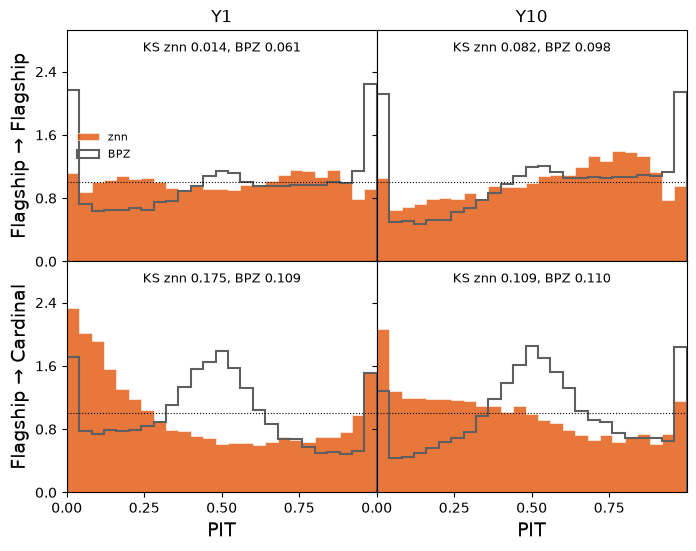

In [10]:
from matplotlib.ticker import MaxNLocator

pit_bins = np.linspace(0, 1, 26)
top = 0
fig, axes = plt.subplots(2, 2, figsize=(8, 6), sharex=True, sharey=True, gridspec_kw=dict(hspace=0, wspace=0))
for row, test_sim in enumerate(TEST_SIMS):
    for col, scenario in enumerate(SCENARIOS):
        ax = axes[row, col]
        ks = []
        for method in METHODS:
            c = (test_sim, scenario, method)
            style = dict(histtype="stepfilled", alpha=0.8, ec="white", lw=0.5) if method == "znn" else dict(
                histtype="step", lw=1.5)
            heights, _, _ = ax.hist(pits[c], pit_bins, density=True, color=METHOD_COLORS[method],
                                    label=METHOD_LABELS[method], **style)
            top = max(top, heights.max())
            ks.append(f"{METHOD_LABELS[method]} {results[c]['ks']:.3f}")
        ax.axhline(1, color="k", lw=0.8, ls=":")
        ax.text(0.5, 0.95, "KS " + ", ".join(ks), transform=ax.transAxes, ha="center", va="top", fontsize=9,
                bbox=dict(fc="white", ec="none", alpha=0.8, pad=1))
        if row == 0:
            ax.set_title(DEPTH_LABELS[scenario], fontsize=12)
        if col == 0:
            ax.set_ylabel(transfer_label(test_sim))
        if row == len(TEST_SIMS) - 1:
            ax.set_xlabel("PIT")
axes[0, 0].legend(fontsize=8, frameon=False, loc="center left")
# with no gaps, keep the ticks off the panel edges so labels of neighbouring panels do not touch
axes[0, 0].set_xlim(0, 1)
axes[0, 0].set_ylim(0, 1.25 * top)  # headroom for the KS labels
axes[0, 0].set_xticks([0, 0.25, 0.5, 0.75])
axes[0, 0].yaxis.set_major_locator(MaxNLocator(nbins=4, prune="upper"))
save(fig, "pit")
plt.show()


### Point estimates

`zmode` against the reference redshift on the held-out set (log-density 2D histogram), at each depth, for znn and for BPZ side by side. BPZ's zmode is on its redshift grid, which ends at 3. The dashed lines mark |Δz|/(1+z) = 0.2, the outlier threshold.

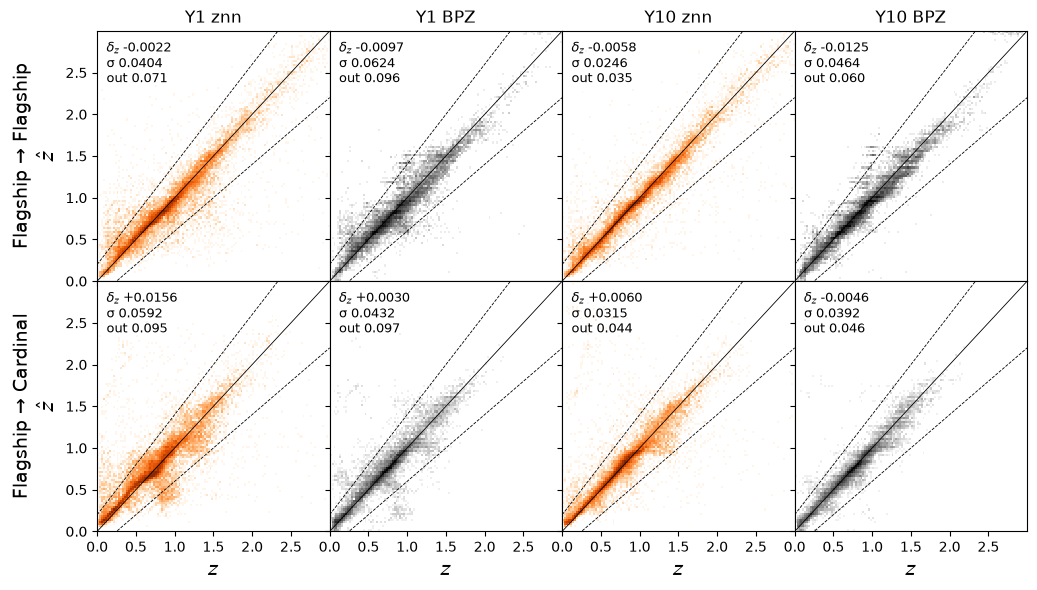

In [11]:
from matplotlib.colors import LogNorm

zb = np.linspace(0, 3, 121)
COLUMNS = list(itertools.product(SCENARIOS, METHODS))
fig, axes = plt.subplots(len(TEST_SIMS), len(COLUMNS), figsize=(3 * len(COLUMNS), 3 * len(TEST_SIMS) + 0.5),
                         sharex=True, sharey=True, gridspec_kw=dict(hspace=0, wspace=0))
for row, test_sim in enumerate(TEST_SIMS):
    for col, (scenario, method) in enumerate(COLUMNS):
        ax = axes[row, col]
        key = (test_sim, scenario, method)
        h = heldout[key]
        ax.hist2d(h["z_ref"], h["zmode"], bins=[zb, zb], cmap=METHOD_CMAPS[method], norm=LogNorm(), rasterized=True)
        ax.plot(zb, zb, color="k", lw=0.6)
        for sgn in (-1, 1):
            ax.plot(zb, zb + sgn * 0.2 * (1 + zb), color="k", lw=0.6, ls="--")
        v = table.loc[key]
        ax.text(0.04, 0.96, f"$\\delta_z$ {v['mean']:+.4f}\nσ {v['std']:.4f}\nout {v['abs_outlier_rate']:.3f}",
                transform=ax.transAxes, va="top", fontsize=9)
        if row == 0:
            ax.set_title(f"{DEPTH_LABELS[scenario]} {METHOD_LABELS[method]}", fontsize=12)
        if col == 0:
            ax.set_ylabel(f"{transfer_label(test_sim)}\n$\\hat{{z}}$")
        if row == len(TEST_SIMS) - 1:
            ax.set_xlabel("$z$")
axes[0, 0].set_xlim(0, 3)
axes[0, 0].set_ylim(0, 3)
# ticks stop short of 3 so labels of neighbouring panels do not touch
axes[0, 0].set_xticks(np.arange(0, 3, 0.5))
axes[0, 0].set_yticks(np.arange(0, 3, 0.5))
save(fig, "zphot_vs_zref")
plt.show()


### n(z)

The predicted n(z) of each held-out set against its reference redshifts. One redshift is drawn from every object's p(z) and the draws are histogrammed. Repeating this `N_NZ_DRAWS` times gives the predicted n(z) in each bin (points: the mean over the draws, i.e. the stacked p(z); znn and BPZ in their colours, offset slightly in z) and its uncertainty (error bars: the standard deviation over the draws). If the p(z)s are calibrated, the histogram of the reference redshifts (black) is one more such draw and should agree with the points within the error bars. The grey shadow is the n(z) of the Flagship training split the model was trained on: on Flagship it matches the held-out histogram, on Cardinal it shows how far Cardinal's redshift distribution is from what the model learned.

The table compares the two distributions, predicted minus reference: `Δ<z>` is the change in mean redshift and `Δσ_z` the change in width (standard deviation), both averaged over the draws, per method. `KS` is the two-sample Kolmogorov-Smirnov statistic between the reference redshifts and all the draws pooled, i.e. the stacked p(z).

In [12]:
from matplotlib.ticker import MaxNLocator
from scipy.stats import ks_2samp

NZ_BINS = np.linspace(0, 3, 61)
NZ_CENTRES = 0.5 * (NZ_BINS[1:] + NZ_BINS[:-1])
N_NZ_DRAWS = 1_000
nz_rng = np.random.default_rng(NZ_SEED)


def nz_hist(z):
    # n(z) normalised over all objects, so draws outside NZ_BINS (e.g. z < 0) lower it rather than being dropped
    return np.histogram(z, NZ_BINS)[0] / (len(z) * np.diff(NZ_BINS))


# the 80% of the training file each model was trained on, per depth
nz_train = {}
for scenario in SCENARIOS:
    train = znn.read_catalog(path("training", TASKSET, TRAIN_SIM, scenario))
    idx_train, _ = train_test_split(np.arange(len(train)), test_size=VAL_FRAC, random_state=SEED)
    nz_train[scenario] = nz_hist(reference_redshifts(train)[idx_train])

# predicted and reference n(z), and the metrics, by (test sim, depth, method)
nz_pred, nz_true, nz_metrics = {}, {}, {}
for key, h in heldout.items():
    z_draws = h["pz"].rvs(size=N_NZ_DRAWS, random_state=nz_rng)  # (objects, draws)
    nz_pred[key] = np.stack([nz_hist(zd) for zd in z_draws.T])
    nz_true[key] = nz_hist(h["z_ref"])
    nz_metrics[key] = {
        "Δ<z>": z_draws.mean(axis=0).mean() - h["z_ref"].mean(),
        "Δσ_z": z_draws.std(axis=0).mean() - h["z_ref"].std(),
        "KS": ks_2samp(h["z_ref"], z_draws.ravel()).statistic,
    }

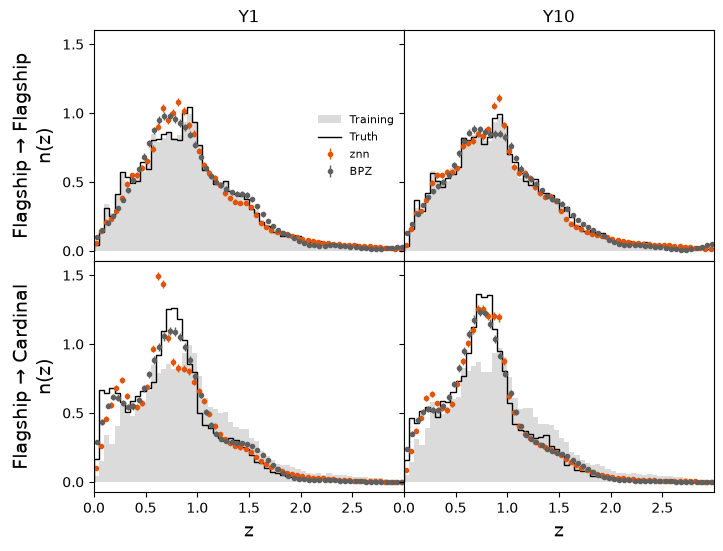

\begin{table}[htbp]
\caption{Predicted against held-out n(z) of the task set 3 models trained on Flagship (znn) and of BPZ with its prior fitted on Flagship, on Flagship and on Cardinal. Change in mean redshift $\Delta\langle z \rangle$ and in width $\Delta\sigma_z$ (predicted minus reference), and the two-sample Kolmogorov--Smirnov statistic between the reference redshifts and redshifts drawn from the p(z)s.}
\label{tab:nz_metrics}
\begin{tabular}{lllrrr}
\toprule
 &  &  & $\Delta\langle z \rangle$ & $\Delta\sigma_z$ & KS \\
Tested on & Depth & Method &  &  &  \\
\midrule
\multirow[t]{4}{*}{Flagship} & \multirow[t]{2}{*}{Y1} & znn & -0.0034 & -0.0353 & 0.0241 \\
 &  & BPZ & -0.0181 & -0.0504 & 0.0308 \\
 & \multirow[t]{2}{*}{Y10} & znn & -0.0095 & -0.0282 & 0.0148 \\
 &  & BPZ & -0.0205 & -0.0358 & 0.0172 \\
\midrule
\multirow[t]{4}{*}{Cardinal} & \multirow[t]{2}{*}{Y1} & znn & 0.0340 & -0.0016 & 0.0414 \\
 &  & BPZ & 0.0188 & -0.0097 & 0.0300 \\
 & \multirow[t]{2}{*}{Y10} & znn & 0.0

Δ<z>    Δσ_z      KS
test     scenario method                        
flagship 1yr      znn    -0.0034 -0.0353  0.0241
                  bpz    -0.0181 -0.0504  0.0308
         10yr     znn    -0.0095 -0.0282  0.0148
                  bpz    -0.0205 -0.0358  0.0172
cardinal 1yr      znn     0.0340 -0.0016  0.0414
                  bpz     0.0188 -0.0097  0.0300
         10yr     znn     0.0196 -0.0045  0.0289
                  bpz    -0.0077 -0.0110  0.0287

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(8, 6), sharex=True, sharey=True, gridspec_kw=dict(hspace=0, wspace=0))
# the methods' points are offset by a fraction of a bin so their error bars do not overlap
offsets = dict(zip(METHODS, 0.15 * np.diff(NZ_BINS)[0] * np.linspace(-1, 1, len(METHODS))))
for row, test_sim in enumerate(TEST_SIMS):
    for col, scenario in enumerate(SCENARIOS):
        ax = axes[row, col]
        ax.stairs(nz_train[scenario], NZ_BINS, fill=True, color=TRAIN_COLOR, alpha=0.35, lw=0, label="Training")
        ax.stairs(nz_true[(test_sim, scenario, METHODS[0])], NZ_BINS, color="k", lw=1.0, label="Truth")
        for method in METHODS:
            pred = nz_pred[(test_sim, scenario, method)]
            ax.errorbar(NZ_CENTRES + offsets[method], pred.mean(axis=0), pred.std(axis=0), fmt="o", ms=3, lw=1,
                        capsize=0, color=METHOD_COLORS[method], label=METHOD_LABELS[method])
        if row == 0:
            ax.set_title(DEPTH_LABELS[scenario], fontsize=12)
        if col == 0:
            ax.set_ylabel(f"{transfer_label(test_sim)}\nn(z)")
        if row == len(TEST_SIMS) - 1:
            ax.set_xlabel("z")
axes[0, 0].legend(fontsize=8, frameon=False, loc="center right")
# with no gaps, keep the ticks off the panel edges so labels of neighbouring panels do not touch
axes[0, 0].set_xlim(0, 3)
axes[0, 0].set_xticks(np.arange(0, 3, 0.5))
axes[0, 0].yaxis.set_major_locator(MaxNLocator(nbins=4, prune="upper"))
save(fig, "nz_heldout")
plt.show()

nz_table = pd.DataFrame.from_dict(nz_metrics, orient="index")
nz_table.index.names = table.index.names
save_latex(
    nz_table,
    "nz_metrics",
    {"Δ<z>": r"$\Delta\langle z \rangle$", "Δσ_z": r"$\Delta\sigma_z$", "KS": r"KS"},
    rf"Predicted against held-out n(z) of the task set 3 models trained on Flagship (znn) and of BPZ with its prior fitted on Flagship, on Flagship and on Cardinal. Change in mean redshift $\Delta\langle z \rangle$ and in width $\Delta\sigma_z$ "
    r"(predicted minus reference), and the two-sample Kolmogorov--Smirnov statistic between the reference redshifts and "
    r"redshifts drawn from the p(z)s.",
)
nz_table.round(4)
